<a href="https://colab.research.google.com/github/aymanr8-dot/DS-2002-Walmart-Hurricane-Project_Data-Demons-/blob/main/notebooks/team_notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Walmart Hurricane Analytics — DS 2002 Midterm
**Team Data Demons** · Esther & Ayman · Fall 2026

**Scope of this version:** the data cleaning pipeline, the weather API and join, and **Questions 1–2**. Q3–Q5 are in progress.

**Sources.** Only what the kickoff allows: the five project data files (read from the team repo), the Open-Meteo API
(weather and geocoding, no key needed), and the *Walmart Case* the project assumes. The transactions cover **September 1–30, 2024** across 12 Florida stores. The timing of the storm comes
from the Open-Meteo weather data itself (section 3.2), not from outside reporting.

**How to run:** `Runtime → Restart and run all` (Colab) or `Kernel → Restart & Run All` (Jupyter).
The notebook reads the data files from a local `data/` folder if it finds one (repo checkout, or files uploaded to Colab),
otherwise straight from the team repo on GitHub.
The weather call uses Open-Meteo, which needs no API key.

| Section | What it does |
|---|---|
| 0 | Setup and data loading |
| 1 | Cleaning pipeline (functions), row counts before/after |
| 2 | Profile raw vs. clean, five worst problems, SKU consolidation, decision log |
| 3 | Weather API (retries, timezone alignment, checked join, storm timing from the data) |
| 4 | **Q1** Demand surge |
| 5 | **Q2** SKU consolidation |

## 0. Setup

In [1]:
import os, re, time, json, sqlite3, urllib.parse, urllib.request
from datetime import date

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mtick

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

# ---- Analysis constants (every one of these is a decision; see the decision log) ----
BASELINE_START, BASELINE_END = pd.Timestamp("2024-09-01"), pd.Timestamp("2024-09-14")
SURGE_SEARCH_START = pd.Timestamp("2024-09-15")  # first day after the baseline
DATA_DIR = "data"                                # local folder for the weather cache
os.makedirs(DATA_DIR, exist_ok=True)

# ---- Chart style: one validated categorical order, thin marks, recessive grid ----
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
MUTED = "#8a8984"
plt.rcParams.update({
    "figure.figsize": (10, 4.8), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ae", "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 10.5, "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "legend.frameon": False, "lines.linewidth": 2, "axes.axisbelow": True,
})

def shade_windows(ax, arrival=None, alpha=0.10):
    """Shade the baseline window; if given, mark the day the storm reached the stores (from the weather data)."""
    ax.axvspan(BASELINE_START, BASELINE_END + pd.Timedelta(days=1), color=MUTED, alpha=alpha, lw=0)
    ymax = ax.get_ylim()[1]
    ax.text(BASELINE_START + pd.Timedelta(hours=6), ymax * 0.97, "baseline", va="top", fontsize=9, color="#52514e")
    if arrival is not None:
        ax.axvline(arrival + pd.Timedelta(hours=12), color="#52514e", ls="--", lw=1)
        ax.text(arrival + pd.Timedelta(hours=18), ymax * 0.97, "storm arrives", va="top", ha="left", fontsize=9, color="#52514e")

## 1. Cleaning pipeline
One function per problem, chained in `clean_transactions()`. Every function writes its decision and the rows it touched
to `decision_log`. Nothing is silently dropped except exact duplicates: returns and rows with no timestamp are **kept and flagged**.

In [2]:
import os
import re
import numpy as np
import pandas as pd
import requests

DATA_URL = ('https://raw.githubusercontent.com/aymanr8-dot/DS-2002-Walmart-Hurricane-Project_Data-Demons-/'
            'main/data/')

def data_path(name, folders=('data', '../data', '/content')):
    """Local copy if there is one (repo checkout, or a file uploaded to Colab), otherwise the team repo on GitHub."""
    for folder in folders:
        p = os.path.join(folder, name)
        if os.path.exists(p):
            return p
    return DATA_URL + name

raw = pd.read_csv(data_path('walmart_transactions.csv'), dtype=str)
stores_raw = pd.read_csv(data_path('store_locations.csv'), dtype=str)

decision_log = []

def log_decision(step, decision, rows_touched, rows_after):
    decision_log.append({'step': step, 'decision': decision,
                         'rows_touched': int(rows_touched), 'rows_after': int(rows_after)})

def drop_duplicates(df):
    dupes = df.duplicated()
    out = df[~dupes].copy()
    log_decision('duplicates', 'Dropped exact duplicate rows (same transaction_id and every field)',
                 dupes.sum(), len(out))
    return out

def clean_store_id(s):
    """' FL-330', 'FL_330', 'FL330', 'fl-330' -> 'FL-330'"""
    s = s.astype(str).str.strip().str.upper().str.replace(r'[^A-Z0-9]', '', regex=True)
    return s.str.replace(r'^([A-Z]{2})(\d+)$', r'\1-\2', regex=True)

def standardize_store_ids(df):
    before = df['store_id']
    df['store_id'] = clean_store_id(before)
    log_decision('store_id', f"Stripped spaces, upper-cased, rewrote to FL-### "
                 f"({before.nunique()} spellings -> {df['store_id'].nunique()} stores)",
                 (before != df['store_id']).sum(), len(df))
    return df

def parse_unit_price(df):
    had_dollar = df['unit_price'].str.contains(r'\$', na=False)
    df['unit_price'] = pd.to_numeric(df['unit_price'].str.replace(r'[$,\s]', '', regex=True),
                                     errors='coerce')
    assert df['unit_price'].notna().all(), 'some unit_price values did not convert'
    log_decision('unit_price', "Removed leading '$' and converted text to float",
                 had_dollar.sum(), len(df))
    return df

def flag_returns(df):
    df['quantity'] = pd.to_numeric(df['quantity']).astype(int)
    df['is_return'] = df['quantity'] < 0
    log_decision('quantity', 'Negative quantities treated as returns: kept, flagged is_return=True, '
                 'excluded from demand counts', df['is_return'].sum(), len(df))
    return df

TS_FORMATS = ['%Y-%m-%d %H:%M:%S',   # 2024-09-13 20:30:20
              '%Y-%m-%dT%H:%M:%S',   # 2024-09-24T09:48:13
              '%m/%d/%Y %H:%M',      # 09/26/2024 09:26
              '%m-%d-%Y %H:%M:%S',   # 09-23-2024 18:24:47
              '%d-%b-%Y %H:%M']      # 21-Sep-2024 19:46

def parse_timestamps(df):
    s = df['timestamp'].str.strip()
    parsed = pd.Series(pd.NaT, index=df.index, dtype='datetime64[ns]')
    for fmt in TS_FORMATS:
        parsed = parsed.fillna(pd.to_datetime(s, format=fmt, errors='coerce'))
    unparsed = s.notna() & parsed.isna()
    assert unparsed.sum() == 0, f'{unparsed.sum()} timestamps in an unknown format'
    reformatted = s.notna() & ~s.str.match(r'^\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2}$', na=False)
    df['timestamp'] = parsed
    log_decision('timestamp', f'Parsed {len(TS_FORMATS)} text formats to datetime (store-local time)',
                 reformatted.sum(), len(df))
    df['timestamp_missing'] = df['timestamp'].isna()
    log_decision('timestamp', 'Missing timestamps flagged (timestamp_missing=True), not dropped: still count '
                 'for SKU/product totals, left out of anything time-based', df['timestamp_missing'].sum(), len(df))
    return df

CATEGORY_MAP = {'emergency': 'Emergency', 'emergency supplies': 'Emergency',
                'grocery': 'Grocery', 'groceries': 'Grocery',
                'electronics': 'Electronics',
                'entertainment': 'Entertainment', 'games & entertainment': 'Entertainment',
                'household': 'Household', 'household essentials': 'Household',
                'baby': 'Baby', 'baby products': 'Baby',
                'breakfast': 'Breakfast', 'breakfast foods': 'Breakfast',
                'alcohol': 'Alcohol', 'alcoholic beverages': 'Alcohol',
                'snacks': 'Snacks',
                'health': 'Health', 'health & wellness': 'Health'}

def standardize_categories(df):
    before = df['category']
    df['category'] = before.str.strip().str.lower().map(CATEGORY_MAP)
    assert df['category'].notna().all(), 'unmapped category label'
    log_decision('category', f"Mapped {before.nunique()} category spellings to {df['category'].nunique()} categories",
                 (before != df['category']).sum(), len(df))
    df['product_name'] = df['product_name'].str.strip()
    return df

STORE_TZ = {'FL-710': 'America/Chicago'}   # Pensacola is on Central time; every other store is Eastern
GEOCODE_URL = 'https://geocoding-api.open-meteo.com/v1/search'   # same provider as the weather data, no key

def geocode_city(city, state='Florida'):
    """City -> (lat, lon) from Open-Meteo's geocoding API, keeping only matches in the right US state."""
    r = requests.get(GEOCODE_URL, params={'name': city, 'count': 20}, timeout=30)
    r.raise_for_status()
    hits = [h for h in r.json().get('results', []) if h.get('admin1') == state and h.get('country_code') == 'US']
    assert hits, f'no geocoding match for {city}, {state}'
    return hits[0]['latitude'], hits[0]['longitude']

def clean_stores(stores):
    s = stores.copy()
    s['store_id'] = clean_store_id(s['store_id'])
    s = s.drop_duplicates('store_id').copy()            # FL239 / FL_287 were repeat rows
    s['state'] = 'FL'                                    # 'Florida', 'Fla.' -> 'FL'
    s['region'] = s['region'].str.strip()
    s[['latitude', 'longitude']] = s[['latitude', 'longitude']].astype(float)
    for i in s.index[s['latitude'].isna()]:              # Tallahassee had blank coordinates: look them up
        s.loc[i, ['latitude', 'longitude']] = geocode_city(s.loc[i, 'city'])
    s['tz'] = s['store_id'].map(STORE_TZ).fillna('America/New_York')
    return s.reset_index(drop=True)

def clean_transactions(df):
    df = drop_duplicates(df)
    df = standardize_store_ids(df)
    df = parse_unit_price(df)
    df = flag_returns(df)
    df = parse_timestamps(df)
    df = standardize_categories(df)
    return df.reset_index(drop=True)

sales = clean_transactions(raw)
stores = clean_stores(stores_raw)

print(f'rows before cleaning: {len(raw):,}')
print(f'rows after cleaning:  {len(sales):,}')
print(f'rows removed:         {len(raw) - len(sales):,}')
print(f"returns flagged (kept): {sales['is_return'].sum():,}")
print(f"missing timestamps flagged (kept): {sales['timestamp_missing'].sum():,}")
print(f"store file: {len(stores_raw)} rows -> {len(stores)} stores after dedupe")
unjoined = set(sales['store_id']) - set(stores['store_id'])
print('store_ids that do not join to the store file:', unjoined or 'none')
print('date range:', sales['timestamp'].min(), 'to', sales['timestamp'].max())
sales.head()

rows before cleaning: 25,562
rows after cleaning:  25,532
rows removed:         30
returns flagged (kept): 130
missing timestamps flagged (kept): 884
store file: 14 rows -> 12 stores after dedupe
store_ids that do not join to the store file: none
date range: 2024-09-01 06:01:15 to 2024-09-30 22:57:47


,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price,is_return,timestamp_missing
0,TXN012636,FL-710,2024-09-24 09:48:13,PNUTBTR-16,PEANUT BUTTER,Grocery,1,3.15,False,False
1,TXN000759,FL-412,2024-09-13 20:30:20,CNSOUP-01,CANNED SOUP,Grocery,1,2.02,False,False
2,TXN003338,FL-105,2024-09-17 10:06:00,TOILETPAPER12,Toilet Paper 12-Roll,Household,2,10.47,False,False
3,TXN025020,FL-330,2024-09-11 06:29:08,ROKU-STD,Roku Streaming Stick,Electronics,1,28.59,False,False
4,TXN015797,FL-302,2024-09-26 15:59:42,BEER-24,Light Beer 24pk,Alcohol,3,18.82,False,False


## 2. Profile: raw vs. clean
The cleaning functions copy the data, so `raw` is still the untouched file. Profiling both side by side shows each fix landed.

In [3]:
NULL_TOKENS = {"", "NULL", "N/A", "NA", "NaN", "nan", "None", "null"}

def profile(df, name="df"):
    """Rows, columns, types, nulls (counting text null tokens), distinct values, and a few examples per column."""
    out = []
    for c in df.columns:
        s = df[c]
        is_null = s.isna() | s.astype(str).str.strip().isin(NULL_TOKENS)
        out.append({
            "column": c,
            "dtype": str(s.dtype),
            "null_pct": round(100 * is_null.mean(), 2),
            "distinct": s[~is_null].nunique(),
            "examples": list(s[~is_null].drop_duplicates().head(4)),
        })
    print(f"{name}: {len(df):,} rows x {df.shape[1]} cols | exact duplicate rows: {df.duplicated().sum()}")
    return pd.DataFrame(out).set_index("column")

display(profile(raw, "walmart_transactions (raw)"))
display(profile(sales, "sales (clean)"))

walmart_transactions (raw): 25,562 rows x 8 cols | exact duplicate rows: 30


,dtype,null_pct,distinct,examples
column,,,,
transaction_id,object,0.00,25532,"[TXN012636, TXN000759, TXN003338, TXN025020]"
store_id,object,0.00,60,"[FL-710, fl-412, FL-105, FL-330]"
timestamp,object,3.47,23952,"[2024-09-24T09:48:13, 2024-09-13 20:30:20, 202..."
sku,object,0.00,45,"[PNUTBTR-16, CNSOUP-01, TOILETPAPER12, ROKU-STD]"
product_name,object,0.00,63,"[PEANUT BUTTER, CANNED SOUP, Toilet Paper 12-R..."
category,object,0.00,37,"[Grocery, GROCERY, Household Essentials, ELECT..."
quantity,object,0.00,11,"[1, 2, 3, 4]"
unit_price,object,0.00,3668,"[3.15, 2.02, 10.47, 28.59]"


sales (clean): 25,532 rows x 10 cols | exact duplicate rows: 0


,dtype,null_pct,distinct,examples
column,,,,
transaction_id,object,0.00,25532,"[TXN012636, TXN000759, TXN003338, TXN025020]"
store_id,object,0.00,12,"[FL-710, FL-412, FL-105, FL-330]"
timestamp,datetime64[ns],3.46,23417,"[2024-09-24 09:48:13, 2024-09-13 20:30:20, 202..."
sku,object,0.00,45,"[PNUTBTR-16, CNSOUP-01, TOILETPAPER12, ROKU-STD]"
product_name,object,0.00,62,"[PEANUT BUTTER, CANNED SOUP, Toilet Paper 12-R..."
category,object,0.00,10,"[Grocery, Household, Electronics, Alcohol]"
quantity,int64,0.00,11,"[1, 2, 3, 4]"
unit_price,float64,0.00,1667,"[3.15, 2.02, 10.47, 28.59]"
is_return,bool,0.00,2,"[False, True]"


In [4]:
ts_shapes = raw["timestamp"].str.replace(r"\d", "9", regex=True).value_counts(dropna=False)
print("Raw timestamp shapes (digits replaced by 9; NaN = empty/NULL/N/A/NaN/nan):\n", ts_shapes, "\n")
print("store_id spellings:", raw["store_id"].nunique(), "->", sales["store_id"].nunique())
print("category spellings:", raw["category"].nunique(), "->", sales["category"].nunique())
print("product_name spellings:", raw["product_name"].nunique(), "| SKUs:", raw["sku"].nunique())
print("unit_price with $ sign:", raw["unit_price"].str.contains(r"\$").sum())
display(profile(stores_raw, "store_locations (raw)"))

Raw timestamp shapes (digits replaced by 9; NaN = empty/NULL/N/A/NaN/nan):
 timestamp
9999-99-99 99:99:99    12179
99/99/9999 99:99        5031
99-Sep-9999 99:99       2546
9999-99-99T99:99:99     2511
99-99-9999 99:99:99     2409
NaN                      886
Name: count, dtype: int64 

store_id spellings: 60 -> 12
category spellings: 37 -> 10
product_name spellings: 63 | SKUs: 45
unit_price with $ sign: 3029
store_locations (raw): 14 rows x 8 cols | exact duplicate rows: 0


,dtype,null_pct,distinct,examples
column,,,,
store_id,object,0.00,14,"[FL-239, FL-105, FL-330, FL-412]"
store_name,object,0.00,12,"[Walmart Supercenter Orlando, Walmart Supercen..."
city,object,0.00,12,"[Orlando, Tampa, Miami, Jacksonville]"
state,object,0.00,3,"[FL, Florida, Fla.]"
zip_code,object,0.00,12,"[32801, 33602, 33101, 32099]"
latitude,object,7.14,11,"[28.5383, 27.9506, 25.7617, 30.3322]"
longitude,object,7.14,11,"[-81.3792, -82.4572, -80.1918, -81.6557]"
region,object,0.00,7,"[Central, West, South, North]"


### The five worst problems (from the profile)
1. **Timestamps come in five formats plus five spellings of "missing".** `2024-09-12 08:15:00`, `2024-09-12T08:15:00`, `09/12/2024 08:15`, `12-Sep-2024 08:15`, `09-12-2024 08:15:00`, and 886 rows (3.5%) that are empty, `NULL`, `N/A`, `NaN` or `nan`. Q1 and the weather join both run on dates, so this comes first.
2. **The same product sits under several SKUs.** 45 SKUs, but only 20 real products. Strawberry Pop-Tarts alone appears as `PT-12`, `SKU#459812`, `POPTART-STRAW` and `PT_STRAWBERRY`. The product name is spelled 63 ways.
3. **`store_id` has 60 spellings for 12 stores.** `FL-239`, `fl-239`, `FL_239`, `FL239`, and `" FL-239"` with a leading space. The store file itself has two duplicate stores (`FL239`, `FL_287`), and Tallahassee has no coordinates.
4. **`category` has 37 spellings for 10 categories.** Case (`EMERGENCY` / `emergency`) and synonyms (`Emergency Supplies`, `Groceries`, `Games & Entertainment`, `Alcoholic Beverages`, `Baby Products`).
5. **Numbers stored as text.** `unit_price` is text, and 3,029 values (12%) start with `$`. `quantity` has 130 negative values (returns), and 30 rows are exact duplicates.

### 2.1 SKU consolidation mapping (needed by Q2)
**Method.** In the transaction file, each SKU is sold under several product-name spellings, and those spellings are *shared*
across SKUs (`HD Tarp` appears under both `TARP-HD` and `HDTARP-01`). We link SKUs that share a normalized product name
(a union-find over the SKU–name graph). Each connected group is one real product. This is data-driven, so we don't have to
guess that `PT-12` and `SKU#459812` are the same Pop-Tart: the cashiers' name strings tell us. We then review every group by
hand and give it a canonical name.

In [5]:
def norm_text(s):
    return s.astype(str).str.strip().str.lower().str.replace(r"\s+", " ", regex=True)

def build_sku_map(tx, catalog):
    """Group SKUs that share a normalized product name in POS data; return one row per SKU."""
    pairs = pd.DataFrame({"sku": tx["sku"].str.strip().str.upper(), "name": norm_text(tx["product_name"])}).drop_duplicates()
    parent = {}
    def find(x):
        parent.setdefault(x, x)
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x
    for sku, name in pairs.itertuples(index=False):
        a, b = find("S:" + sku), find("N:" + name)
        if a != b:
            parent[a] = b
    skus = sorted(set(pairs["sku"]) | set(catalog["sku"].str.strip().str.upper()))
    groups = {}
    for sku in skus:
        groups.setdefault(find("S:" + sku), []).append(sku)
    return groups

# Hand-reviewed canonical names, keyed by any one SKU in the group
CANONICAL = {
    "PT-12": ("P01", "Pop-Tarts Strawberry"),        "WTR-24": ("P02", "Bottled Water 24-Pack"),
    "BATT-100": ("P03", "AA Batteries 4-Pack"),      "FLASH-01": ("P04", "LED Flashlight"),
    "BEER-24": ("P05", "Light Beer 24-Pack"),        "BG-MONO": ("P06", "Monopoly Board Game"),
    "CARDS-01": ("P07", "Playing Cards"),            "STREAM-01": ("P08", "Roku Streaming Stick"),
    "SOUP-CAN": ("P09", "Canned Soup"),              "BREAD-WH": ("P10", "White Bread"),
    "PB-16": ("P11", "Peanut Butter 16oz"),          "CNDL-EM": ("P12", "Emergency Candles"),
    "FAID-01": ("P13", "First Aid Kit"),             "CHRG-PORT": ("P14", "Portable Phone Charger"),
    "CHIPS-VP": ("P15", "Chips Variety Pack"),       "PTOWEL-6": ("P16", "Paper Towels 6-Roll"),
    "TP-12": ("P17", "Toilet Paper 12-Roll"),        "DIAP-S3": ("P18", "Diapers Size 3"),
    "BFORM-01": ("P19", "Infant Formula"),           "TARP-HD": ("P20", "Heavy Duty Tarp"),
}

def sku_mapping_table(tx_raw, cat_raw):
    groups = build_sku_map(tx_raw, cat_raw)
    rows = []
    for members in groups.values():
        keys = [s for s in members if s in CANONICAL]
        assert len(keys) == 1, f"group {members} needs exactly one canonical entry, found {keys}"
        pid, pname = CANONICAL[keys[0]]
        rows += [{"sku": s, "product_id": pid, "product": pname, "skus_in_group": len(members)} for s in members]
    m = pd.DataFrame(rows).sort_values(["product_id", "sku"]).reset_index(drop=True)
    # Category per product: normalize every category label seen for its SKUs; it must be unanimous.
    t = pd.DataFrame({"sku": tx_raw["sku"].str.strip().str.upper(), "category": norm_text(tx_raw["category"]).map(CATEGORY_MAP)})
    cat = t.merge(m, on="sku").groupby("product_id")["category"].agg(lambda x: sorted(x.dropna().unique()))
    assert (cat.str.len() == 1).all(), f"products with conflicting categories:\n{cat[cat.str.len() != 1]}"
    m["category"] = m["product_id"].map(cat.str[0])
    return m

catalog_raw = pd.read_csv(data_path('product_catalog.csv'), dtype=str)
SKU_MAP = sku_mapping_table(raw, catalog_raw)
print(f"{SKU_MAP['sku'].nunique()} SKUs -> {SKU_MAP['product_id'].nunique()} products")
SKU_MAP

45 SKUs -> 20 products


,sku,product_id,product,skus_in_group,category
0,POPTART-STRAW,P01,Pop-Tarts Strawberry,4,Breakfast
1,PT-12,P01,Pop-Tarts Strawberry,4,Breakfast
2,PT_STRAWBERRY,P01,Pop-Tarts Strawberry,4,Breakfast
3,SKU#459812,P01,Pop-Tarts Strawberry,4,Breakfast
4,WATER24PK,P02,Bottled Water 24-Pack,3,Emergency
5,WTR-24,P02,Bottled Water 24-Pack,3,Emergency
6,WTR_24PK,P02,Bottled Water 24-Pack,3,Emergency
7,BAT-AA4,P03,AA Batteries 4-Pack,3,Emergency
8,BATT-100,P03,AA Batteries 4-Pack,3,Emergency
9,BATT_AA_4PK,P03,AA Batteries 4-Pack,3,Emergency


### 2.2 Apply the mapping and finish the analysis table
Adds the canonical product to every row, a calendar `date`, and `revenue`. Also logs the store-file fixes made inside
`clean_stores()`, so the decision log covers every file we touched.

In [6]:
n_before = len(sales)
sales = sales.merge(SKU_MAP[["sku", "product_id", "product", "category"]].rename(columns={"category": "product_category"}),
                    on="sku", how="left", validate="many_to_one")
assert len(sales) == n_before and sales["product_id"].notna().all(), "SKU mapping changed the row count or left a SKU unmapped"
assert (sales["category"] == sales["product_category"]).all(), "row category disagrees with the product's category"
sales = sales.drop(columns="product_category")
sales["product_name_raw"] = sales["product_name"]
sales["product_name"] = sales["product"]
sales = sales.drop(columns="product")
log_decision("sku", f"Mapped {sales['sku'].nunique()} SKUs to {sales['product_id'].nunique()} products via SKU_MAP; "
             "canonical name in product_name, original kept in product_name_raw",
             (sales["product_name_raw"] != sales["product_name"]).sum(), len(sales))

sales["date"] = sales["timestamp"].dt.normalize()
sales["revenue"] = sales["quantity"] * sales["unit_price"]

# Store-file decisions made inside clean_stores()
log_decision("stores", "Normalized store ids and dropped repeat stores (FL239 = FL-239, FL_287 = FL-287)",
             len(stores_raw) - len(stores), len(stores))
log_decision("stores", "Set state 'Florida' / 'Fla.' to 'FL'", (stores_raw["state"] != "FL").sum(), len(stores))
log_decision("stores", "FL-619 Tallahassee had blank lat/lon: looked up with Open-Meteo's geocoding API (same provider as the weather data)",
             stores_raw["latitude"].isna().sum(), len(stores))
log_decision("stores", "Added each store's timezone: Pensacola FL-710 is Central, the rest are Eastern", len(stores), len(stores))

# Analysis views used by Q1-Q2
demand = sales[~sales["is_return"]]                      # units sold (returns excluded)
dated_sales = demand[~demand["timestamp_missing"]]       # ... that also have a usable date

# Catalog with the canonical product attached (Q2 uses it to show the catalog's internal conflicts)
catalog = catalog_raw.assign(sku=catalog_raw["sku"].str.strip().str.upper()).merge(
    SKU_MAP[["sku", "product_id", "product"]], on="sku", how="left", validate="one_to_one")
catalog = catalog.rename(columns={"category": "category_raw"})
catalog["unit_cost"] = pd.to_numeric(catalog["unit_cost"])
assert catalog["product_id"].notna().all()

pd.Series({
    "rows": len(sales), "stores": sales["store_id"].nunique(), "SKUs": sales["sku"].nunique(),
    "products": sales["product_id"].nunique(), "categories": sales["category"].nunique(),
    "returns (kept, flagged)": int(sales["is_return"].sum()),
    "no timestamp (kept, flagged)": int(sales["timestamp_missing"].sum()),
    "rows used for by-date analysis": len(dated_sales),
}).to_frame("clean table")

,clean table
rows,25532
stores,12
SKUs,45
products,20
categories,10
"returns (kept, flagged)",130
"no timestamp (kept, flagged)",884
rows used for by-date analysis,24521


### 2.3 Decision log

In [7]:
with pd.option_context("display.max_colwidth", 150):
    display(pd.DataFrame(decision_log))

,step,decision,rows_touched,rows_after
0,duplicates,Dropped exact duplicate rows (same transaction_id and every field),30,25532
1,store_id,"Stripped spaces, upper-cased, rewrote to FL-### (60 spellings -> 12 stores)",4345,25532
2,unit_price,Removed leading '$' and converted text to float,3026,25532
3,quantity,"Negative quantities treated as returns: kept, flagged is_return=True, excluded from demand counts",130,25532
4,timestamp,Parsed 5 text formats to datetime (store-local time),12479,25532
5,timestamp,"Missing timestamps flagged (timestamp_missing=True), not dropped: still count for SKU/product totals, left out of anything time-based",884,25532
6,category,Mapped 37 category spellings to 10 categories,18744,25532
7,sku,"Mapped 45 SKUs to 20 products via SKU_MAP; canonical name in product_name, original kept in product_name_raw",17319,25532
8,stores,"Normalized store ids and dropped repeat stores (FL239 = FL-239, FL_287 = FL-287)",2,12
9,stores,Set state 'Florida' / 'Fla.' to 'FL',4,12


### 2.4 Daily order volume
A sanity check before any question: what does a normal day look like, and when does the data start moving?

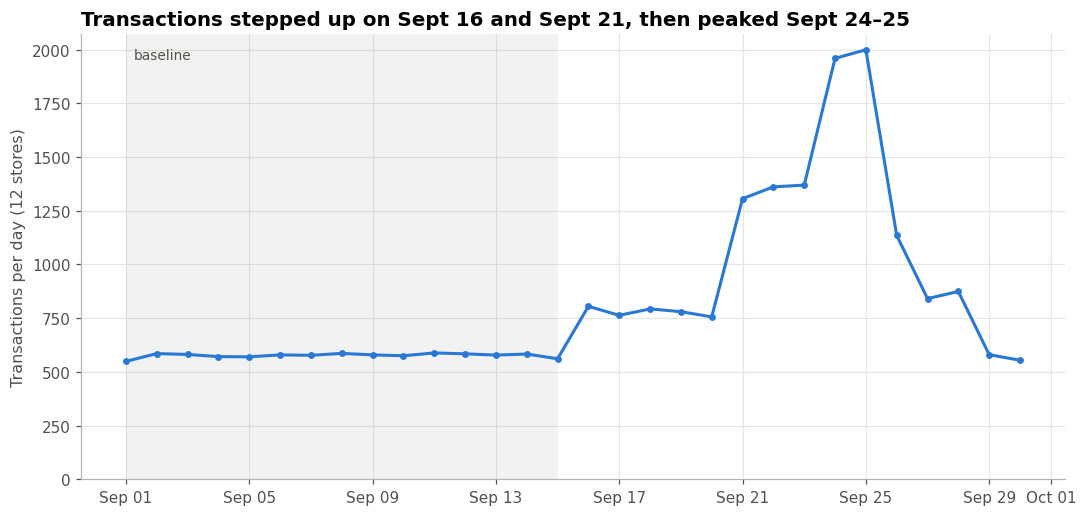

In [8]:
daily_orders = dated_sales.groupby("date")["transaction_id"].nunique()

fig, ax = plt.subplots()
ax.plot(daily_orders.index, daily_orders.values, color=PALETTE[0], marker="o", ms=3.5)
ax.set_title("Transactions stepped up on Sept 16 and Sept 21, then peaked Sept 24–25")
ax.set_ylabel("Transactions per day (12 stores)")
ax.set_xlabel("")
ax.set_ylim(0)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
shade_windows(ax)
plt.tight_layout(); plt.show()

## 3. Weather API: Open-Meteo historical archive
**Source:** `https://archive-api.open-meteo.com/v1/archive` (Open-Meteo historical weather, no key needed).

**Timezone handling.** We request hourly data **in GMT on purpose** (`timezone=GMT`), the way the case's weather feed
arrived (Walmart Case, Exhibit 3). Then we convert each store's hours to that store's own local time before rolling up to calendar days. Sales
timestamps are local store time, so a storm hour at 02:00 GMT on Sept 27 is 10 pm EDT on **Sept 26** in Orlando, and 9 pm CDT
in Pensacola. Rolling up in GMT would push late-evening weather into the wrong sales day.

In [9]:
ARCHIVE_URL = "https://archive-api.open-meteo.com/v1/archive"
HOURLY_VARS = ["precipitation", "wind_speed_10m", "wind_gusts_10m", "pressure_msl"]
WEATHER_CACHE = os.path.join(DATA_DIR, "weather_hourly_gmt_cache.csv")

def fetch_hourly_weather(lat, lon, start, end, retries=4, backoff=2.0, timeout=30):
    """One Open-Meteo archive call with retries and exponential backoff. Returns hourly rows with a GMT timestamp."""
    params = {
        "latitude": lat, "longitude": lon, "start_date": start, "end_date": end,
        "hourly": ",".join(HOURLY_VARS), "timezone": "GMT",
        "wind_speed_unit": "mph", "precipitation_unit": "inch",
    }
    for attempt in range(1, retries + 1):
        try:
            r = requests.get(ARCHIVE_URL, params=params, timeout=timeout)
            if r.status_code == 429 or r.status_code >= 500:
                raise requests.HTTPError(f"HTTP {r.status_code}")
            r.raise_for_status()
            payload = r.json()
            break
        except (requests.RequestException, ValueError) as e:
            if attempt == retries:
                raise
            wait = backoff ** attempt
            print(f"  attempt {attempt} failed ({e}); retrying in {wait:.0f}s")
            time.sleep(wait)
    assert payload.get("utc_offset_seconds", 0) == 0, "expected GMT timestamps from the API"
    h = pd.DataFrame(payload["hourly"])
    h["time_gmt"] = pd.to_datetime(h.pop("time")).dt.tz_localize("UTC")
    h["source"] = f"open-meteo archive ({ARCHIVE_URL})"
    return h

def get_store_weather(stores, start="2024-08-31", end="2024-10-01"):
    """Hourly GMT weather for every store. One day of padding each side so local days at the edges are complete."""
    frames = []
    try:
        for s in stores.itertuples():
            h = fetch_hourly_weather(s.latitude, s.longitude, start, end)
            h["store_id"] = s.store_id
            frames.append(h)
            time.sleep(0.3)   # be polite to a free API
        hourly = pd.concat(frames, ignore_index=True)
        hourly.to_csv(WEATHER_CACHE, index=False)   # cache of a real call, used only if a later run can't reach the API
    except Exception as e:
        if not os.path.exists(WEATHER_CACHE):
            raise
        print(f"API unavailable ({e}); loading cache of a previous successful call: {WEATHER_CACHE}")
        hourly = pd.read_csv(WEATHER_CACHE)
        hourly["time_gmt"] = pd.to_datetime(hourly["time_gmt"], utc=True)
        hourly["source"] = hourly["source"] + " [cached]"
    return hourly

def hourly_to_local_daily(hourly, stores):
    """Convert GMT hours to each store's local time, then roll up to local calendar days."""
    h = hourly.merge(stores[["store_id", "tz"]], on="store_id", how="left", validate="many_to_one")
    h["time_local"] = [t.tz_convert(z).tz_localize(None) for t, z in zip(h["time_gmt"], h["tz"])]
    h["date"] = h["time_local"].dt.normalize()
    d = (h.groupby(["store_id", "date"])
           .agg(precip_in=("precipitation", "sum"),
                max_wind_mph=("wind_speed_10m", "max"),
                max_gust_mph=("wind_gusts_10m", "max"),
                min_pressure_hpa=("pressure_msl", "min"),
                hours=("time_local", "size"),
                source=("source", "first"))
           .reset_index())
    d = d[d["date"].between("2024-09-01", "2024-09-30")]
    assert (d["hours"] >= 23).all() and (d["hours"] <= 25).all(), "incomplete local days after timezone conversion"
    return d.reset_index(drop=True)

weather_hourly = get_store_weather(stores)
weather_daily = hourly_to_local_daily(weather_hourly, stores)
print(f"hourly rows: {len(weather_hourly):,} | daily rows: {len(weather_daily)} (expected 12 stores x 30 days = 360)")
weather_daily.head()

hourly rows: 9,216 | daily rows: 360 (expected 12 stores x 30 days = 360)


,store_id,date,precip_in,max_wind_mph,max_gust_mph,min_pressure_hpa,hours,source
0,FL-078,2024-09-01,0.059,7.0,21.5,1011.9,24,open-meteo archive (https://archive-api.open-m...
1,FL-078,2024-09-02,0.114,5.1,17.0,1011.9,24,open-meteo archive (https://archive-api.open-m...
2,FL-078,2024-09-03,0.315,10.1,22.1,1013.9,24,open-meteo archive (https://archive-api.open-m...
3,FL-078,2024-09-04,0.614,9.5,21.3,1016.8,24,open-meteo archive (https://archive-api.open-m...
4,FL-078,2024-09-05,0.525,8.6,18.1,1015.4,24,open-meteo archive (https://archive-api.open-m...


In [10]:
# Show the timezone shift with one real hour: the same GMT hour lands on different local dates.
ex = weather_hourly[(weather_hourly["time_gmt"] == pd.Timestamp("2024-09-27 02:00", tz="UTC")) &
                    weather_hourly["store_id"].isin(["FL-239", "FL-710"])].merge(stores[["store_id", "city", "tz"]], on="store_id")
ex["local_time"] = [t.tz_convert(z) for t, z in zip(ex["time_gmt"], ex["tz"])]
ex[["store_id", "city", "time_gmt", "local_time", "wind_gusts_10m"]]

,store_id,city,time_gmt,local_time,wind_gusts_10m
0,FL-239,Orlando,2024-09-27 02:00:00+00:00,2024-09-26 22:00:00-04:00,54.6
1,FL-710,Pensacola,2024-09-27 02:00:00+00:00,2024-09-26 21:00:00-05:00,33.8


### 3.1 The checked join: daily sales × daily weather
Grain is **store × local date**. We build the full 12 × 30 grid first, so a store-day with zero sales still appears as 0
and doesn't silently disappear. Then we check the row count, the key coverage, and the nulls.

In [11]:
grid = pd.MultiIndex.from_product([sorted(stores["store_id"]), pd.date_range("2024-09-01", "2024-09-30")],
                                  names=["store_id", "date"]).to_frame(index=False)
store_day = (dated_sales.groupby(["store_id", "date"])
             .agg(units=("quantity", "sum"), transactions=("transaction_id", "nunique"), revenue=("revenue", "sum"))
             .reset_index())
store_day = grid.merge(store_day, on=["store_id", "date"], how="left").fillna({"units": 0, "transactions": 0, "revenue": 0})

joined = store_day.merge(weather_daily, on=["store_id", "date"], how="outer", validate="one_to_one", indicator=True)
check = {
    "sales rows": len(store_day), "weather rows": len(weather_daily), "joined rows": len(joined),
    "matched both": int((joined["_merge"] == "both").sum()),
    "sales only": int((joined["_merge"] == "left_only").sum()),
    "weather only": int((joined["_merge"] == "right_only").sum()),
    "null weather values": int(joined[["precip_in", "max_gust_mph", "min_pressure_hpa"]].isna().sum().sum()),
    "units preserved": bool(np.isclose(joined["units"].sum(), dated_sales["quantity"].sum())),
}
assert check["joined rows"] == check["matched both"] == 360, check
assert check["null weather values"] == 0 and check["units preserved"], check
joined = joined.drop(columns="_merge")
pd.Series(check).to_frame("join check")

,join check
sales rows,360
weather rows,360
joined rows,360
matched both,360
sales only,0
weather only,0
null weather values,0
units preserved,True


### 3.2 When did the storm reach the stores?
Q1 asks whether sales rose *ahead of landfall*. We date the storm from our own weather data, not from outside reporting.
**Storm arrival** is the day the store-average max wind gust peaks, and we show the day pressure bottoms out as a check.
Q1 uses the arrival day as the end of the surge window.

In [12]:
statewide_wx = joined.groupby("date")[["max_gust_mph", "precip_in", "min_pressure_hpa"]].mean()
STORM_ARRIVAL = statewide_wx["max_gust_mph"].idxmax()
print(f"Storm arrival (peak store-average gust): {STORM_ARRIVAL:%b %d}, {statewide_wx['max_gust_mph'].max():.0f} mph | "
      f"lowest pressure: {statewide_wx['min_pressure_hpa'].idxmin():%b %d}, {statewide_wx['min_pressure_hpa'].min():.0f} hPa")
statewide_wx.loc["2024-09-14":"2024-09-30"].round(2)

Storm arrival (peak store-average gust): Sep 26, 58 mph | lowest pressure: Sep 26, 996 hPa


,max_gust_mph,precip_in,min_pressure_hpa
date,,,
2024-09-14,20.69,0.38,1010.81
2024-09-15,17.07,0.13,1010.80
2024-09-16,19.30,0.25,1011.42
2024-09-17,16.72,0.26,1011.91
2024-09-18,20.15,0.41,1011.30
2024-09-19,15.85,0.10,1009.42
2024-09-20,17.72,0.02,1009.40
2024-09-21,21.27,0.02,1011.24
2024-09-22,17.85,0.03,1011.18


## 4. Q1: Demand surge
**Question.** Which categories surged before the storm, and by how much?

**Baseline: Sept 1–14.** We can defend this window on four counts.
- It is **two full weeks, Sunday to Saturday**, so each day of the week appears exactly twice and weekend shopping doesn't bias it.
- It **ends 12 days before the storm reaches the stores** in our weather data (Sept 26, section 3.2), while gusts and pressure are normal.
- It is **flat**: the coefficient of variation is computed below.
- It **leaves a buffer week (Sept 15–20)**. If buying started early, it doesn't contaminate the baseline.

**Surge window: chosen by the data, not by us.** These are the days between Sept 15 and the storm's arrival (`STORM_ARRIVAL`,
section 3.2) where total units exceed the baseline mean + 3 standard deviations.

In [13]:
daily_units = dated_sales.groupby("date")["quantity"].sum()
base = daily_units[BASELINE_START:BASELINE_END]
threshold = base.mean() + 3 * base.std()
candidates = daily_units[SURGE_SEARCH_START:STORM_ARRIVAL]
surge_days = candidates[candidates > threshold].index
SURGE_START, SURGE_END = surge_days.min(), surge_days.max()
assert len(surge_days) == (SURGE_END - SURGE_START).days + 1, "surge days are not contiguous"

print(f"Baseline: {BASELINE_START:%b %d}-{BASELINE_END:%b %d}, mean {base.mean():.0f} units/day, "
      f"CV {base.std() / base.mean():.1%}, threshold (mean + 3 SD) = {threshold:.0f}")
print(f"Surge window: {SURGE_START:%b %d}-{SURGE_END:%b %d} ({len(surge_days)} days), "
      f"mean {daily_units[SURGE_START:SURGE_END].mean():.0f} units/day")
print(f"Left out of Q1 for missing timestamps: {demand['timestamp_missing'].sum()} sale rows "
      f"({demand['timestamp_missing'].mean():.1%})")

Baseline: Sep 01-Sep 14, mean 1109 units/day, CV 2.9%, threshold (mean + 3 SD) = 1206
Surge window: Sep 16-Sep 26 (11 days), mean 2347 units/day
Left out of Q1 for missing timestamps: 881 sale rows (3.5%)


In [14]:
def window_rate(df, start, end, by):
    """Average units per day over a window, by a grouping column."""
    n_days = (end - start).days + 1
    w = df[(df["date"] >= start) & (df["date"] <= end)]
    return w.groupby(by)["quantity"].sum() / n_days

def lift_table(df, by, base=(BASELINE_START, BASELINE_END), surge=None):
    surge = surge or (SURGE_START, SURGE_END)
    t = pd.DataFrame({"baseline_units_per_day": window_rate(df, *base, by),
                      "surge_units_per_day": window_rate(df, *surge, by)})
    t["extra_units_per_day"] = t["surge_units_per_day"] - t["baseline_units_per_day"]
    t["lift_pct"] = 100 * (t["surge_units_per_day"] / t["baseline_units_per_day"] - 1)
    return t.sort_values("lift_pct", ascending=False).round(1)

cat_lift = lift_table(dated_sales, "category")
top5 = cat_lift.head(5).index.tolist()
cat_lift

,baseline_units_per_day,surge_units_per_day,extra_units_per_day,lift_pct
category,,,,
Breakfast,73.9,311.5,237.6,321.4
Emergency,356.6,860.9,504.3,141.4
Electronics,69.9,149.0,79.1,113.1
Health,42.4,83.7,41.4,97.7
Entertainment,102.6,201.8,99.2,96.6
Alcohol,61.6,119.6,58.1,94.3
Household,85.4,156.5,71.1,83.3
Grocery,172.3,273.4,101.1,58.7
Baby,85.2,121.1,35.9,42.1


In [15]:
# The surge window is not one flat block. Break it into phases and show lift vs. baseline for each.
PHASES = {
    "early build (Sep 16-20)": ("2024-09-16", "2024-09-20"),
    "surge (Sep 21-23)":       ("2024-09-21", "2024-09-23"),
    "peak (Sep 24-25)":        ("2024-09-24", "2024-09-25"),
    "storm arrives (Sep 26)":  ("2024-09-26", "2024-09-26"),
    "after (Sep 27-28)":       ("2024-09-27", "2024-09-28"),
}
base_rate = window_rate(dated_sales, BASELINE_START, BASELINE_END, "category")
phase_lift = pd.DataFrame({
    name: 100 * (window_rate(dated_sales, pd.Timestamp(a), pd.Timestamp(b), "category") / base_rate - 1)
    for name, (a, b) in PHASES.items()
})
total_phase = {name: 100 * (daily_units[a:b].mean() / base.mean() - 1) for name, (a, b) in PHASES.items()}
phase_lift.loc["ALL CATEGORIES"] = total_phase
print("Lift vs. Sept 1-14 baseline, % (peak multiple = 1 + lift/100)")
phase_lift.sort_values("peak (Sep 24-25)", ascending=False).round(0)

Lift vs. Sept 1-14 baseline, % (peak multiple = 1 + lift/100)


,early build (Sep 16-20),surge (Sep 21-23),peak (Sep 24-25),storm arrives (Sep 26),after (Sep 27-28)
category,,,,,
Breakfast,116.0,388.0,740.0,311.0,129.0
Emergency,47.0,183.0,315.0,143.0,67.0
Electronics,32.0,150.0,268.0,99.0,47.0
ALL CATEGORIES,38.0,144.0,254.0,101.0,53.0
Health,36.0,106.0,246.0,87.0,65.0
Entertainment,30.0,116.0,228.0,110.0,53.0
Alcohol,23.0,145.0,205.0,75.0,23.0
Household,32.0,99.0,195.0,69.0,46.0
Grocery,24.0,83.0,126.0,24.0,39.0


In [16]:
# Does the answer depend on the baseline we picked? Re-run with two other defensible windows.
alt = {
    "Sept 1-14 (chosen)": (BASELINE_START, BASELINE_END),
    "Sept 8-14 (last clean week)": (pd.Timestamp("2024-09-08"), BASELINE_END),
    "Sept 1-20 (everything pre-surge)": (BASELINE_START, pd.Timestamp("2024-09-20")),
}
sens = pd.DataFrame({k: lift_table(dated_sales, "category", base=v)["lift_pct"] for k, v in alt.items()})
sens["rank_chosen"] = sens.iloc[:, 0].rank(ascending=False).astype(int)
print("Top 5 under each baseline:")
for k in alt:
    print(f"  {k:<34}", sens[k].sort_values(ascending=False).head(5).index.tolist())
sens.round(0)

Top 5 under each baseline:
  Sept 1-14 (chosen)                 ['Breakfast', 'Emergency', 'Electronics', 'Health', 'Entertainment']
  Sept 8-14 (last clean week)        ['Breakfast', 'Emergency', 'Electronics', 'Health', 'Alcohol']
  Sept 1-20 (everything pre-surge)   ['Breakfast', 'Emergency', 'Electronics', 'Entertainment', 'Alcohol']


,Sept 1-14 (chosen),Sept 8-14 (last clean week),Sept 1-20 (everything pre-surge),rank_chosen
category,,,,
Alcohol,94.0,101.0,84.0,6
Baby,42.0,40.0,36.0,9
Breakfast,321.0,319.0,228.0,1
Electronics,113.0,115.0,97.0,3
Emergency,141.0,142.0,117.0,2
Entertainment,97.0,94.0,84.0,5
Grocery,59.0,59.0,50.0,8
Health,98.0,105.0,82.0,4
Household,83.0,84.0,70.0,7


In [17]:
# Missing timestamps: are they spread evenly? If they cluster in one category, Q1 would be biased.
miss_share = pd.DataFrame({
    "share_of_all_sales": demand.groupby("category")["quantity"].sum() / demand["quantity"].sum(),
    "share_of_undated_sales": demand[demand["timestamp_missing"]].groupby("category")["quantity"].sum() / demand.loc[demand["timestamp_missing"], "quantity"].sum(),
}).mul(100).round(1)
miss_share["gap_pts"] = (miss_share["share_of_undated_sales"] - miss_share["share_of_all_sales"]).round(1)
miss_share.sort_values("gap_pts")

,share_of_all_sales,share_of_undated_sales,gap_pts
category,,,
Emergency,34.8,33.7,-1.1
Grocery,13.2,12.2,-1.0
Baby,6.2,5.4,-0.8
Health,3.7,3.1,-0.6
Entertainment,8.9,8.8,-0.1
Alcohol,5.2,5.2,0.0
Electronics,6.4,6.7,0.3
Snacks,3.9,4.5,0.6
Breakfast,10.5,11.4,0.9


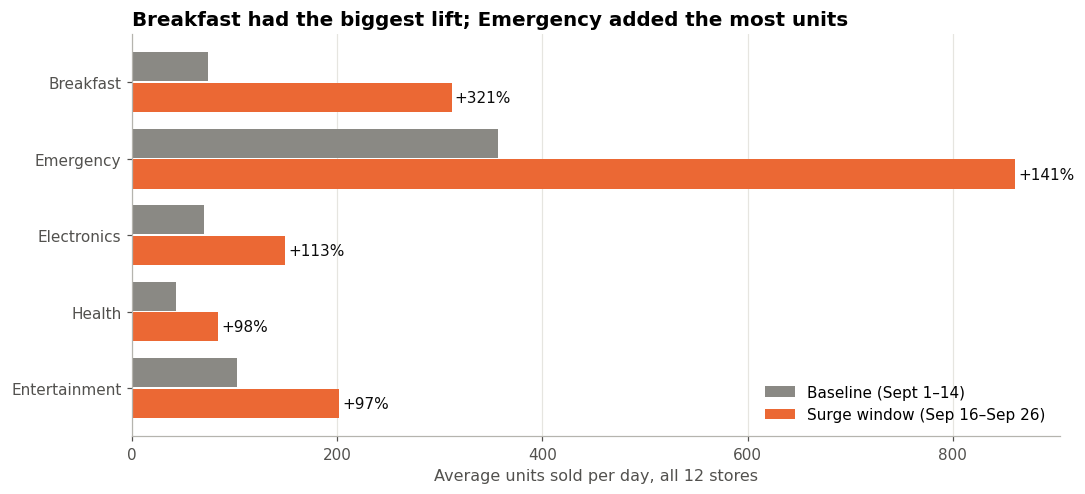

In [18]:
# Chart: baseline vs surge, top 5 categories by lift
plot = cat_lift.loc[top5].iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 4.6))
y = np.arange(len(plot))
ax.barh(y + 0.2, plot["baseline_units_per_day"], height=0.38, color=MUTED, label="Baseline (Sept 1–14)")
ax.barh(y - 0.2, plot["surge_units_per_day"], height=0.38, color=PALETTE[1],
        label=f"Surge window ({SURGE_START:%b %d}–{SURGE_END:%b %d})")
for yi, (_, r) in zip(y, plot.iterrows()):
    ax.text(r["surge_units_per_day"] + 3, yi - 0.2, f"+{r['lift_pct']:.0f}%", va="center", fontsize=10, color="#0b0b0b")
ax.set_yticks(y, plot.index)
ax.set_xlabel("Average units sold per day, all 12 stores")
ax.set_title(f"{top5[0]} had the biggest lift; {cat_lift['extra_units_per_day'].idxmax()} added the most units")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

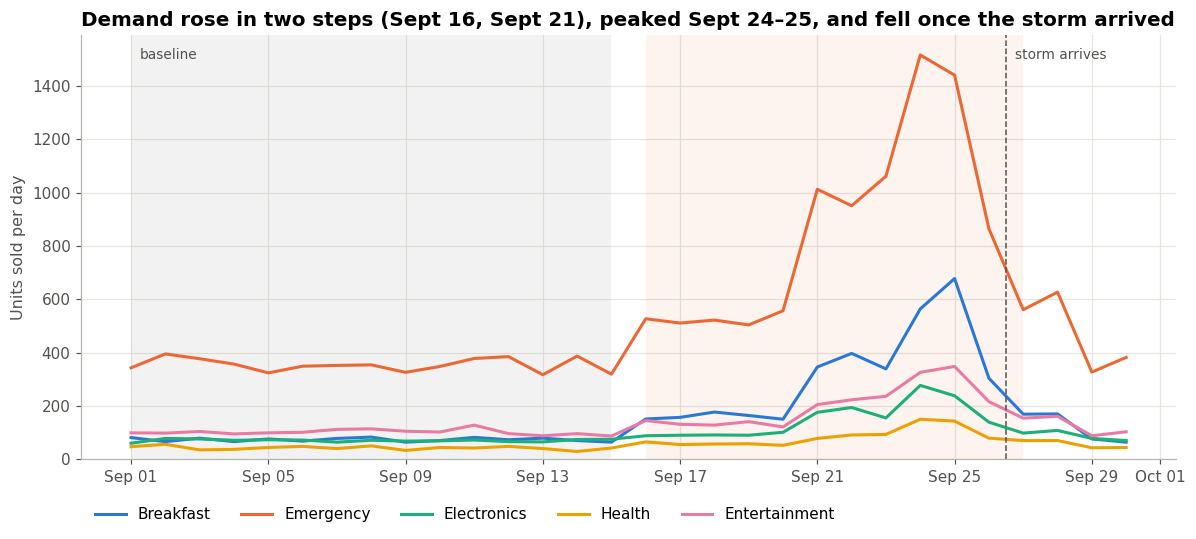

In [19]:
# Chart: daily units for the top 5 categories over the month
daily_cat = dated_sales.groupby(["date", "category"])["quantity"].sum().unstack().fillna(0)
fig, ax = plt.subplots(figsize=(11, 5))
for i, c in enumerate(top5):
    ax.plot(daily_cat.index, daily_cat[c], color=PALETTE[i], label=c)
ax.set_title("Demand rose in two steps (Sept 16, Sept 21), peaked Sept 24–25, and fell once the storm arrived")
ax.set_ylabel("Units sold per day")
ax.set_ylim(0)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ax.axvspan(SURGE_START, SURGE_END + pd.Timedelta(days=1), color=PALETTE[1], alpha=0.08, lw=0)
shade_windows(ax, arrival=STORM_ARRIVAL)
ax.legend(loc="upper left", ncol=5, bbox_to_anchor=(0, -0.08))
plt.tight_layout(); plt.show()

In [20]:
q1 = cat_lift
print(f"Q1 numbers: surge window {SURGE_START:%b %d}–{SURGE_END:%b %d}; total units/day "
      f"{base.mean():.0f} -> {daily_units[SURGE_START:SURGE_END].mean():.0f} "
      f"(+{100 * (daily_units[SURGE_START:SURGE_END].mean() / base.mean() - 1):.0f}%)")
for c, r in q1.head(5).iterrows():
    print(f"  {c:<14} {r.baseline_units_per_day:>6.1f} -> {r.surge_units_per_day:>6.1f} units/day  (+{r.lift_pct:.0f}%)")
print(f"Smallest lift: {q1.index[-1]} (+{q1['lift_pct'].iloc[-1]:.0f}%)")

Q1 numbers: surge window Sep 16–Sep 26; total units/day 1109 -> 2347 (+112%)
  Breakfast        73.9 ->  311.5 units/day  (+321%)
  Emergency       356.6 ->  860.9 units/day  (+141%)
  Electronics      69.9 ->  149.0 units/day  (+113%)
  Health           42.4 ->   83.7 units/day  (+98%)
  Entertainment   102.6 ->  201.8 units/day  (+97%)
Smallest lift: Snacks (+17%)


### Q1 finding
*Every number here is printed by the cells above.*

**Baseline and window.** Sept 1–14 is flat: about 1,109 units/day with a coefficient of variation of 2.9%. Every day from
**Sept 16 through the storm's arrival on Sept 26** (the peak-gust day in our weather data) clears the mean + 3 SD
threshold of 1,206 units/day, so that is our surge window. Over it, total volume averaged **2,347 units/day (+112%)**.
The window has clear phases:
- **Early build (Sept 16–20):** +38%. The weather data still shows normal gusts and pressure here (section 3.2).
- **Second step (Sept 21–23):** +144%.
- **Peak (Sept 24–25):** +254%, about **3.5× normal**.
- **Storm arrives (Sept 26):** volume fell back to +101%.
- **Sept 29:** back to normal.

**Top 5 categories by lift (Sept 16–26 vs. baseline):**
1. **Breakfast +321%.** This is entirely Strawberry Pop-Tarts. At the Sept 24–25 peak it hit **8.4× normal (+740%)**, similar to the Pop-Tarts jump in the Walmart Case (Exhibit 2: +600%, or 7×).
2. **Emergency +141%.** It is the biggest by volume, adding **~504 extra units/day**: water, batteries, flashlights, candles and tarps. At the peak it ran at 4.2× normal.
3. **Electronics +113%.** Portable chargers and streaming sticks.
4. **Health +98%.** First-aid kits.
5. **Entertainment +97%.** Monopoly and playing cards.

Snacks barely moved (+17%), which is a useful control: not *everything* goes up.

**Is this robust?** Breakfast, Emergency and Electronics stay at #1–3 under all three baselines we tried. Health,
Entertainment and Alcohol trade places for #4–5, separated by only a few points, so treat 4–6 as a tie. The 3.5% of
sales with no timestamp fall across categories within 2 points of each category's share of all sales, so leaving them
out does not bias the ranking.

**For leadership:** the buying window opens **about 10 days before the storm reaches the stores** and peaks **two days
before** it. Emergency needs the most trucks. Pop-Tarts needs the biggest *relative* increase, about 8× at the peak.

## 5. Q2: SKU consolidation
**Question.** How much does SKU fragmentation hide, and what does the picture look like once SKUs are consolidated?

The mapping table (`SKU_MAP`, section 2.1) maps 45 SKUs to 20 products. Below: the mapping, then before vs. after.

In [21]:
SKU_MAP.groupby(["product_id", "product", "category"])["sku"].agg(lambda s: ", ".join(s)).reset_index().rename(columns={"sku": "SKUs merged"})

,product_id,product,category,SKUs merged
0,P01,Pop-Tarts Strawberry,Breakfast,"POPTART-STRAW, PT-12, PT_STRAWBERRY, SKU#459812"
1,P02,Bottled Water 24-Pack,Emergency,"WATER24PK, WTR-24, WTR_24PK"
2,P03,AA Batteries 4-Pack,Emergency,"BAT-AA4, BATT-100, BATT_AA_4PK"
3,P04,LED Flashlight,Emergency,"FLASH-01, LED-FLASH"
4,P05,Light Beer 24-Pack,Alcohol,"BEER-24, LTBEER24"
5,P06,Monopoly Board Game,Entertainment,"BG-MONO, GAME-MONO, MONOPOLY-01"
6,P07,Playing Cards,Entertainment,"CARDS-01, PLAYCARD-STD"
7,P08,Roku Streaming Stick,Electronics,"ROKU-STD, STREAM-01"
8,P09,Canned Soup,Grocery,"CNSOUP-01, SOUP-CAN"
9,P10,White Bread,Grocery,"BREAD-WH, WHITEBREAD"


In [22]:
# Catalog conflicts inside the same product: these are why the catalog can't be trusted for cost or pack size
conf = catalog.groupby("product").agg(
    skus=("sku", "count"),
    names=("product_name", "nunique"),
    raw_categories=("category_raw", "nunique"),
    unit_cost_min=("unit_cost", "min"), unit_cost_max=("unit_cost", "max"),
    package_sizes=("package_size", lambda s: ", ".join(sorted(s.dropna().unique()))),
    suppliers=("supplier", lambda s: ", ".join(sorted(s.dropna().unique()))),
)
conf["cost_spread_pct"] = (100 * (conf["unit_cost_max"] / conf["unit_cost_min"] - 1)).round(0)
conf.sort_values("skus", ascending=False).head(8)

,skus,names,raw_categories,unit_cost_min,unit_cost_max,package_sizes,suppliers,cost_spread_pct
product,,,,,,,,
Pop-Tarts Strawberry,4,3,3,1.93,2.26,"4 pack, 4-pack, 4pk, 6 pack","Campbell's, Johnson & Johnson, Roku Inc, Sara Lee",17.0
AA Batteries 4-Pack,3,2,2,3.71,4.16,"24 pack, 4pk, 6 pack","3M Company, Anheuser-Busch, Kimberly-Clark",12.0
Monopoly Board Game,3,2,2,9.96,12.51,"1pk, 24-pack","Campbell's, Georgia-Pacific, Kimberly-Clark",26.0
Bottled Water 24-Pack,3,3,2,2.08,2.64,"1 pack, 24 pack","Frito-Lay, Sara Lee",27.0
Chips Variety Pack,2,2,2,4.03,4.11,"4-pack, single","Frito-Lay, Generic Supplier",2.0
Canned Soup,2,2,2,1.19,1.23,single,"Generic Supplier, J.M. Smucker",3.0
First Aid Kit,2,2,1,6.90,7.85,4 pack,"Anheuser-Busch, J.M. Smucker",14.0
Diapers Size 3,2,2,2,13.59,14.40,"6 pack, single","Generic Supplier, Procter & Gamble",6.0


In [23]:
surge_sales = dated_sales[(dated_sales["date"] >= SURGE_START) & (dated_sales["date"] <= SURGE_END)]
n_surge_days = (SURGE_END - SURGE_START).days + 1

before = (surge_sales.groupby(["sku", "product_name"])["quantity"].sum() / n_surge_days).rename("units_per_day").reset_index()
before["rank"] = before["units_per_day"].rank(ascending=False, method="min").astype(int)
after_ = (surge_sales.groupby("product_name")["quantity"].sum() / n_surge_days).rename("units_per_day").reset_index()
after_["rank"] = after_["units_per_day"].rank(ascending=False, method="min").astype(int)

pt = "Pop-Tarts Strawberry"
pt_before = before[before["product_name"] == pt].sort_values("rank")
pt_after = after_[after_["product_name"] == pt].iloc[0]
summary = pd.DataFrame({
    "before (by SKU)": [before["sku"].nunique(), int(pt_before["rank"].min()), round(pt_before["units_per_day"].max(), 1),
                        f"{len(pt_before)} separate lines"],
    "after (by product)": [after_["product_name"].nunique(), int(pt_after["rank"]), round(pt_after["units_per_day"], 1),
                           "1 line"],
}, index=["items a buyer has to scan", "best Pop-Tarts rank (surge window)", "Pop-Tarts units/day (largest line)",
          "how Pop-Tarts shows up"])
summary

,before (by SKU),after (by product)
items a buyer has to scan,45,20
best Pop-Tarts rank (surge window),4,1
Pop-Tarts units/day (largest line),81.5,311.5
how Pop-Tarts shows up,4 separate lines,1 line


In [24]:
# Lift before and after: does fragmentation change the % story, the volume story, or both?
sku_lift = lift_table(dated_sales, "sku")
prod_lift = lift_table(dated_sales, "product_name")
pt_skus = SKU_MAP.loc[SKU_MAP["product"] == pt, "sku"]
cmp = pd.concat([sku_lift.loc[pt_skus].assign(level="SKU"),
                 prod_lift.loc[[pt]].assign(level="Product")])
cmp

,baseline_units_per_day,surge_units_per_day,extra_units_per_day,lift_pct,level
POPTART-STRAW,17.9,76.9,59.0,329.0,SKU
PT-12,20.6,81.5,60.9,295.0,SKU
PT_STRAWBERRY,18.4,76.9,58.5,317.3,SKU
SKU#459812,16.9,76.2,59.3,350.0,SKU
Pop-Tarts Strawberry,73.9,311.5,237.6,321.4,Product


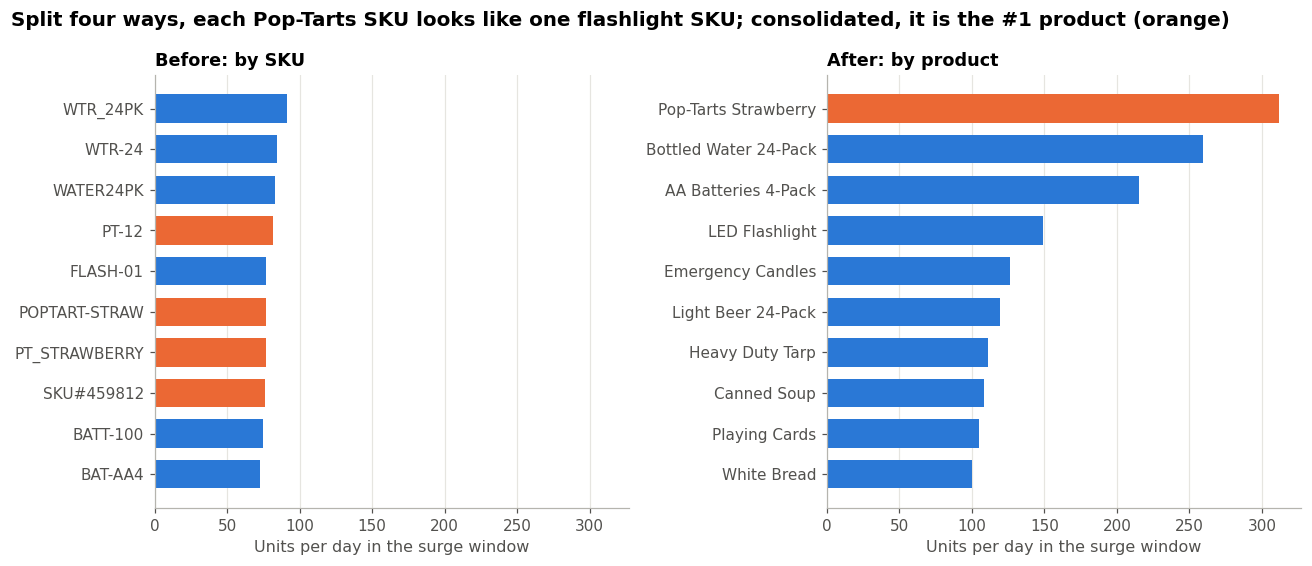

In [25]:
# Chart: top 10 lines in the surge window, by SKU vs. by product
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2), sharex=True)
b10 = before.nlargest(10, "units_per_day").iloc[::-1]
a10 = after_.nlargest(10, "units_per_day").iloc[::-1]
for ax, d, label, title in [(axes[0], b10, "sku", "Before: by SKU"), (axes[1], a10, "product_name", "After: by product")]:
    colors = [PALETTE[1] if (n == pt) else PALETTE[0] for n in d["product_name"]]
    ax.barh(d[label], d["units_per_day"], color=colors, height=0.7)
    ax.set_title(title, fontsize=11.5)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("Units per day in the surge window")
fig.suptitle(f"Split four ways, each Pop-Tarts SKU looks like one flashlight SKU; consolidated, it is the #{int(pt_after['rank'])} product (orange)",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
plt.tight_layout(); plt.show()

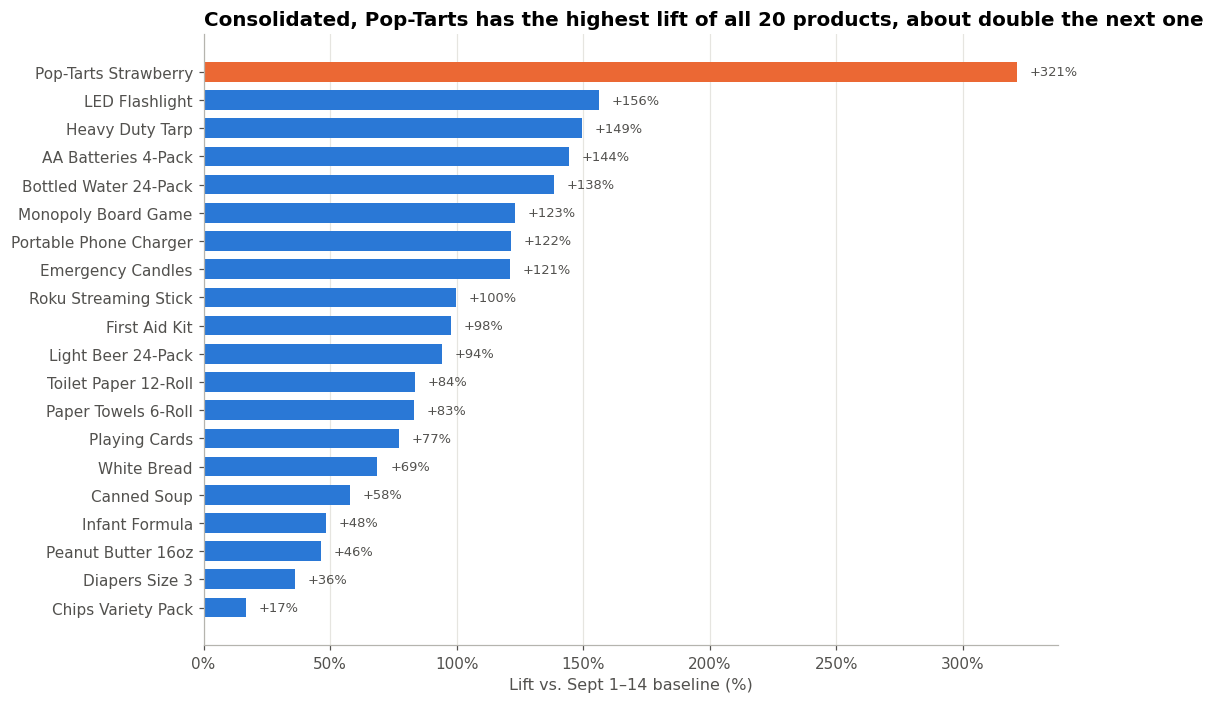

In [26]:
# Chart: product-level lift after consolidation, all 20 products
pl = prod_lift.sort_values("lift_pct")
fig, ax = plt.subplots(figsize=(10, 6.5))
ax.barh(pl.index, pl["lift_pct"], color=[PALETTE[1] if p == pt else PALETTE[0] for p in pl.index], height=0.7)
for i, (p, v) in enumerate(pl["lift_pct"].items()):
    ax.text(v + 5, i, f"+{v:.0f}%", va="center", fontsize=8.5, color="#52514e")
ax.set_title("Consolidated, Pop-Tarts has the highest lift of all 20 products, about double the next one")
ax.set_xlabel("Lift vs. Sept 1–14 baseline (%)")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

In [27]:
pt_lift = prod_lift.loc[pt, "lift_pct"]
print(f"Pop-Tarts: {len(pt_skus)} SKUs -> 1 product | product lift +{pt_lift:.0f}% | "
      f"rank by surge volume {int(pt_before['rank'].min())} (best single SKU) -> {int(pt_after['rank'])} (consolidated)")
print("Product lift ranking (top 6):", prod_lift.head(6)["lift_pct"].to_dict())

Pop-Tarts: 4 SKUs -> 1 product | product lift +321% | rank by surge volume 4 (best single SKU) -> 1 (consolidated)
Product lift ranking (top 6): {'Pop-Tarts Strawberry': 321.4, 'LED Flashlight': 156.1, 'Heavy Duty Tarp': 149.4, 'AA Batteries 4-Pack': 144.5, 'Bottled Water 24-Pack': 138.5, 'Monopoly Board Game': 123.1}


### Q2 finding
*Every number here is printed by the cells above.*

**The mapping.** We consolidated **45 SKUs into 20 products**, linking SKUs that cashiers sold under the same product name.
- Strawberry Pop-Tarts was split across **four** SKUs: `PT-12`, `SKU#459812`, `POPTART-STRAW` and `PT_STRAWBERRY`.
- Bottled water, AA batteries and Monopoly were each split across **three**.
- Every other product was split across two.

**Before vs. after (Sept 16–26 surge window).**
- **By SKU:** the top three lines are all bottled water (~84–92 units/day each). Each Pop-Tarts SKU sells ~76–82
  units/day, about the same as a single flashlight SKU, and they sit at ranks 4, 5, 5 and 8.
- **By product:** Pop-Tarts is the **#1 product at 312 units/day**, ahead of water (259) and batteries (215).

**What changes and what doesn't.** Consolidation leaves the *percentage* lift almost unchanged: each Pop-Tarts SKU shows
+295% to +350%, and the product shows +321%. What it fixes is **size and rank**. A buyer reading a SKU report sees four
ordinary lines, and water at the top. The real answer is that Pop-Tarts is the single biggest-moving product before the
storm, and its lift is the highest of all 20 products, roughly double the next one (LED flashlights, +156%).

**The catalog can't be trusted for anything but the SKU list.** Within the same product:
- Unit costs differ by up to **27%** (water) and 26% (Monopoly).
- Package sizes contradict each other: water is listed as "1 pack" and "24 pack", batteries as "4pk" and "24 pack".
- Suppliers are implausible: Pop-Tarts is listed under Roku Inc and Johnson & Johnson.

That's why we consolidated on POS evidence, not catalog attributes. Any cost or margin analysis should wait for a catalog fix.

**Recommendation:** forecast and replenish at the **product** level, and keep the SKU→product map (`SKU_MAP`) as a
maintained ETL step.